# Trabalho – Rede Neural MLP

Neste notebook, vamos usar os dados do Titanic para treinar uma rede neural que tente prever se um passageiro sobreviveu ou não.

A coluna que queremos prever é `Survived`: 0 significa que não sobreviveu e 1 significa que sobreviveu. O arquivo utilizado é `data/train.csv`, baixado do Kaggle.

## 1. Importação das bibliotecas

In [3]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
ROOT = Path.cwd()

if not (ROOT / "data" / "train.csv").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "train.csv"
MODEL_PATH = ROOT / "models" / "modelo_mlp.joblib"

print("Pasta do projeto:", ROOT)
print("Dataset encontrado:", DATA_PATH.exists())

Pasta do projeto: c:\Users\Leo\Downloads\am-at2-redes-neurais
Dataset encontrado: True


## 2. Conhecendo o problema

O Titanic naufragou em 1912. Neste trabalho, vamos utilizar algumas informações dos passageiros para tentar prever o resultado de cada caso. A tabela abaixo apresenta as colunas que serão utilizadas e o que cada uma representa.

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Arquivo não encontrado: {DATA_PATH}. Baixe train.csv do Kaggle e coloque em data/."
    )

df = pd.read_csv(DATA_PATH)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
colunas = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Survived"]
dicionario = pd.DataFrame({
    "Coluna": colunas,
    "Tipo": [str(df[c].dtype) for c in colunas],
    "Significado": [
        "Classe do bilhete (1ª, 2ª ou 3ª)",
        "Sexo registrado do passageiro",
        "Idade em anos",
        "Quantidade de irmãos/cônjuges a bordo",
        "Quantidade de pais/filhos a bordo",
        "Tarifa paga pelo passageiro",
        "Porto de embarque (C, Q ou S)",
        "Variável alvo: 0 não sobreviveu; 1 sobreviveu"
    ]
})
dicionario

,Coluna,Tipo,Significado
0,Pclass,int64,"Classe do bilhete (1ª, 2ª ou 3ª)"
1,Sex,str,Sexo registrado do passageiro
2,Age,float64,Idade em anos
3,SibSp,int64,Quantidade de irmãos/cônjuges a bordo
4,Parch,int64,Quantidade de pais/filhos a bordo
5,Fare,float64,Tarifa paga pelo passageiro
6,Embarked,str,"Porto de embarque (C, Q ou S)"
7,Survived,int64,Variável alvo: 0 não sobreviveu; 1 sobreviveu


## 3. Conhecendo os dados

In [6]:
print("Dimensões do dataset:", df.shape)
print("\nTipos e valores não nulos:")
df.info()
print("\nValores ausentes:")
display(df.isnull().sum().to_frame("Quantidade de ausentes"))

Dimensões do dataset: (891, 12)

Tipos e valores não nulos:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Valores ausentes:


,Quantidade de ausentes
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [7]:
display(df[colunas].describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
Embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0


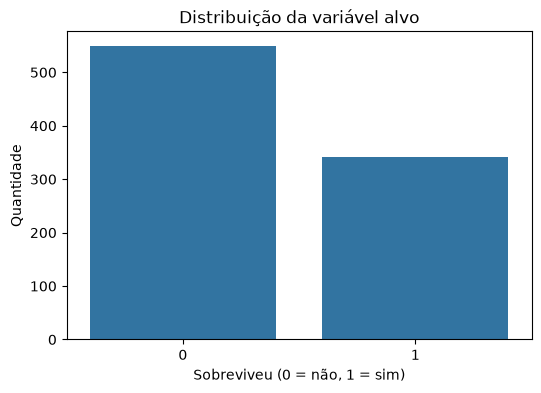

In [8]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")
plt.title("Distribuição da variável alvo")
plt.xlabel("Sobreviveu (0 = não, 1 = sim)")
plt.ylabel("Quantidade")
plt.show()

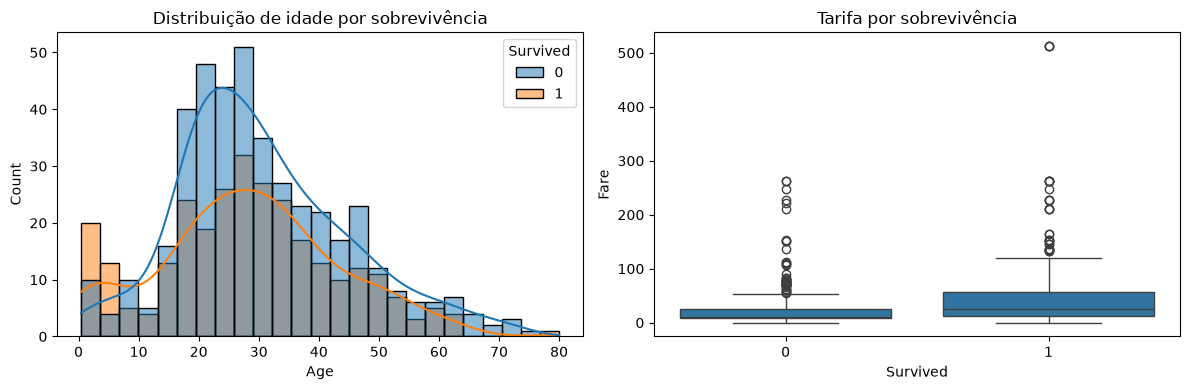

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, kde=True, ax=axes[0])
axes[0].set_title("Distribuição de idade por sobrevivência")
sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[1])
axes[1].set_title("Tarifa por sobrevivência")
plt.tight_layout()
plt.show()

## 4. Preparação dos dados

Foram escolhidas sete colunas para usar na previsão. O identificador, o nome e a cabine não serão utilizados. Alguns campos possuem valores vazios, então eles serão preenchidos durante o pré-processamento. As colunas numéricas serão padronizadas e as categóricas serão transformadas em valores que o modelo consegue utilizar.

In [10]:
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
target = "Survived"

X = df[features].copy()
y = df[target].astype(int)

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,
    random_state=RANDOM_STATE
)

modelo = Pipeline(steps=[
    ("preprocessamento", preprocessor),
    ("mlp", mlp)
])

modelo.fit(X_train, y_train)
print("Treinamento concluído.")

Treinamento concluído.


## 5. Avaliação

Depois do treinamento, o modelo será testado com os dados que ficaram separados. A acurácia mostra a quantidade de previsões corretas em relação ao total. Também serão apresentados precisão, recall, F1-score e a matriz de confusão para observar os acertos e erros em cada classe.

In [11]:
y_pred = modelo.predict(X_test)
acuracia = accuracy_score(y_test, y_pred)

print(f"Acurácia: {acuracia:.4f}")
print("\nRelatório de classificação:")
print(classification_report(
    y_test, y_pred,
    target_names=["Não sobreviveu", "Sobreviveu"],
    zero_division=0
))

Acurácia: 0.8101

Relatório de classificação:
                precision    recall  f1-score   support

Não sobreviveu       0.79      0.95      0.86       110
    Sobreviveu       0.87      0.59      0.71        69

      accuracy                           0.81       179
     macro avg       0.83      0.77      0.78       179
  weighted avg       0.82      0.81      0.80       179



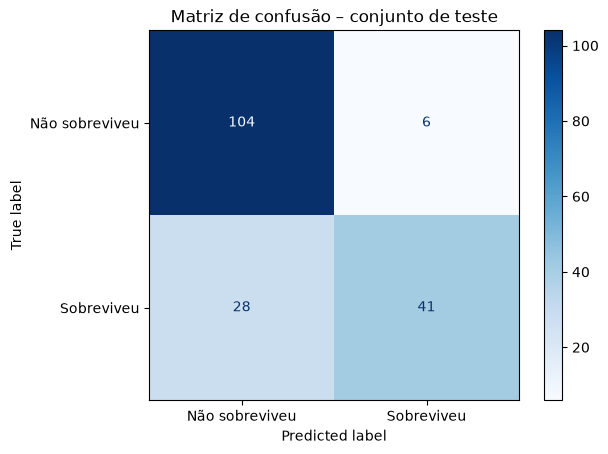

In [12]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Não sobreviveu", "Sobreviveu"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusão – conjunto de teste")
plt.show()

## 6. Salvando o modelo

O pipeline será salvo em um arquivo. Depois, a API poderá carregar esse arquivo e fazer previsões com novos dados, aplicando o mesmo pré-processamento usado no treinamento.

In [13]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(modelo, MODEL_PATH)
print(f"Pipeline salvo em: {MODEL_PATH}")

Pipeline salvo em: c:\Users\Leo\Downloads\am-at2-redes-neurais\models\modelo_mlp.joblib


## 7. Fazendo uma previsão de exemplo

A última célula utiliza os dados de um passageiro fictício para mostrar como o modelo faz uma previsão.

In [14]:
passageiro_exemplo = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "male",
    "Age": 25.0,
    "SibSp": 0,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked": "S"
}])

classe = int(modelo.predict(passageiro_exemplo)[0])
prob = float(modelo.predict_proba(passageiro_exemplo)[0][classe])
print("Classe prevista:", "Sobreviveu" if classe == 1 else "Não sobreviveu")
print(f"Probabilidade da classe prevista: {prob:.4f}")

Classe prevista: Não sobreviveu
Probabilidade da classe prevista: 0.8050
